# Olivia Rodrigo ticket prices: seven-day price-category model

**Question the model answers.** For a show on the Unraveled Tour, given the cheapest listing recorded today, will the cheapest listing **seven days from now** be **Below**, **Typical**, or **Above** what shows normally cost at that point before the concert?

**How "typical" is defined.** We learn it from the GUTS World Tour (a finished tour with full price histories), adjusted so GUTS prices reflect Unraveled Tour price levels.

**What the model does not do.** It does not predict that a price will rise or fall, an exact price, or whether to buy now or wait.

**How the data is split (so nothing is tested on data it learned from)**

| Data | Used for |
|---|---|
| GUTS tour, 86 regular concerts | Typical-price benchmark and model training |
| Unraveled concerts **except** the November 2026 concerts ("development" data) | Price adjustment, model training, and evaluation by cross-validation |
| Unraveled concerts dated **November 2026** ("held out") | Used only for the unseen validation. |


---
# Section 0: Setup and data cleaning

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, classification_report,
                             confusion_matrix, f1_score)
from sklearn.model_selection import GroupKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

pd.set_option("display.width", 150)
pd.set_option("display.max_columns", 30)

# Stages = how many days before the concert a price was recorded.
stages = ["0-7", "8-14", "15-30", "31-60", "61-90", "91+"]
stage_edges = [-1, 7, 14, 30, 60, 90, np.inf]
categories = ["Below", "Typical", "Above"]

horizon_days = 7
random_seed = 42

Some events we captures were not real concert dates, but bus trips and pre-parties. We need to make sure to exclude those or they will skew our results.

In [ ]:
def load_tour(filename, tour_name):
    d = pd.read_csv(filename)
    d = d[d["event_name"].eq("Olivia Rodrigo")].copy()   # real concerts only
    d["date"] = pd.to_datetime(d["date"])
    d["event_date"] = pd.to_datetime(d["event_date"])
    d["tour"] = tour_name
    return d.reset_index(drop=True)

In [ ]:
guts = load_tour("olivia_rodrigo_guts_all_daily_prices.csv", "guts")
unraveled = load_tour("olivia_rodrigo_all_daily_prices_final.csv", "unraveled")

# GUTS shows need a usable history: no hole longer than 14 days, at least 10 priced days.
longest_gap = guts.groupby("event_id")["date"].apply(lambda s: s.sort_values().diff().dt.days.max())
priced_days = guts.groupby("event_id")["get_in"].apply(lambda p: (p > 0).sum())
usable = longest_gap[longest_gap <= 14].index.intersection(priced_days[priced_days >= 10].index)
guts = guts[guts["event_id"].isin(usable)]

# One table with both tours. A price of 0 means "no data". Log prices so that
# "10% higher" means the same for a $100 ticket and a $1000 ticket.
snapshots = pd.concat([guts, unraveled], ignore_index=True)
snapshots["price"] = snapshots["get_in"].where(snapshots["get_in"] > 0)
snapshots["log_price"] = np.log(snapshots["price"])
snapshots["tour_log_price"] = snapshots.groupby(["tour", "date"])["log_price"].transform("median")

# Held-out concerts: every Unraveled concert in November 2026 (scored in Section 5).
concert_info = unraveled.groupby("event_id").agg(
    event_date=("event_date", "first"), venue=("venue", "first"), last_record=("date", "max"))
held_out_ids = set(concert_info[(concert_info["event_date"].dt.year == 2026)
                                & (concert_info["event_date"].dt.month == 11)].index)

print(f"GUTS: {guts['event_id'].nunique()} concerts | Unraveled: {unraveled['event_id'].nunique()} | "
      f"held out for Section 5: {len(held_out_ids)}")


GUTS: 86 concerts | Unraveled: 86 | held out for Section 5: 10


## Price adjustment
Before adjusting prices, we need a baseline for comparison. We group GUTS price observations by how many days remained before each concert and calculate the median price and middle 50% price range for each stage.

We then compare each Unraveled price with the GUTS median for the same stage. For example, a ratio of 1.5 means that an Unraveled price is 50% higher than the GUTS stage median.

In [ ]:
# Assign each usable GUTS observation to a stage before its concert.
# Stage here means a period of time before the concert takes place, not a physical one.
guts_with_stage = guts.loc[guts["get_in"] > 0].copy()
guts_with_stage["days_before_event"] = (
    guts_with_stage["event_date"] - guts_with_stage["date"]
).dt.days

guts_with_stage = guts_with_stage.loc[
    guts_with_stage["days_before_event"] >= 0
].copy()

guts_with_stage["stage"] = pd.cut(
    guts_with_stage["days_before_event"],
    stage_edges,
    labels=stages,
)

# Summarize the GUTS price distribution within each stage.
guts_stage_quantiles = (
    guts_with_stage.groupby("stage", observed=False)["get_in"]
    .quantile([0.25, 0.50, 0.75])
    .unstack()
)
guts_stage_quantiles.columns = ["lower", "median", "upper"]
guts_stage_median = guts_stage_quantiles["median"]


def ratios_to_guts(unraveled_rows):
    """Compare each Unraveled price with the GUTS median at its stage."""
    rows = unraveled_rows.loc[unraveled_rows["get_in"] > 0].copy()
    rows["days_before_event"] = (
        rows["event_date"] - rows["date"]
    ).dt.days

    rows = rows.loc[rows["days_before_event"] >= 0].copy()
    rows["stage"] = pd.cut(
        rows["days_before_event"],
        stage_edges,
        labels=stages,
    ).astype(object)

    reference_price = rows["stage"].map(guts_stage_median)
    rows["ratio_to_guts"] = rows["get_in"] / reference_price
    return rows


development = unraveled.loc[
    ~unraveled["event_id"].isin(held_out_ids)
].copy()
development_ratios = ratios_to_guts(development)

display(guts_stage_quantiles.round(2))

,lower,median,upper
stage,,,
0-7,104.82,161.98,249.14
8-14,113.81,168.22,270.00
15-30,125.06,168.01,291.38
31-60,137.49,180.31,300.65
61-90,139.52,176.97,297.20
91+,177.91,226.40,291.38


We first try the simplest adjustment: one multiplier for the entire tour. Using observations recorded through June 30, 2026, we calculate each concert’s median price ratio, then take the median across concerts.

In [ ]:
# Estimate one multiplier using observations recorded through June 30.
cutoff = pd.Timestamp("2026-06-30")
early = development_ratios.loc[development_ratios["date"] <= cutoff]

early_concert_ratios = (
    early.groupby("event_id")["ratio_to_guts"].median()
)
single_multiplier = float(early_concert_ratios.median())

# Check what multiplier later observations suggest for each stage.
later = development_ratios.loc[development_ratios["date"] > cutoff]

later_concert_ratios = (
    later.groupby(["stage", "event_id"])["ratio_to_guts"].median()
)
later_stage_multipliers = (
    later_concert_ratios.groupby("stage").median().reindex(stages)
)

comparison = pd.DataFrame({
    "Single early multiplier": single_multiplier,
    "Later multiplier by stage": later_stage_multipliers,
})
comparison.index.name = "Days before concert"

display(comparison.round(2))

,Single early multiplier,Later multiplier by stage
Days before concert,,
0-7,1.15,2.01
8-14,1.15,1.60
15-30,1.15,1.87
31-60,1.15,1.65
61-90,1.15,1.91
91+,1.15,1.19


0-7 days prior to the concert prices seem to be more volatile and the single multiplier does not fit the relationship. We will use this custom values to scale the data instead.

In [ ]:
MIN_CONCERTS_PER_STAGE = 5

def compute_stage_scale(unraveled_rows):
    """Estimate one multiplier per stage from concert-level median ratios."""
    ratios = ratios_to_guts(unraveled_rows)

    concert_ratios = (
        ratios.groupby(["stage", "event_id"])["ratio_to_guts"].median()
    )

    stage_summary = (
        concert_ratios.groupby("stage")
        .agg(["median", "count"])
        .reindex(stages)
    )

    # Missing stages count as having zero concerts.
    concert_counts = stage_summary["count"].fillna(0)
    insufficient = concert_counts < MIN_CONCERTS_PER_STAGE

    if insufficient.any():
        missing_stages = stage_summary.index[insufficient].tolist()
        raise ValueError(
            f"Not enough concerts to estimate scales for: {missing_stages}"
        )

    return stage_summary["median"]


STAGE_SCALE = compute_stage_scale(development)

actual_unraveled_medians = (
    development_ratios.groupby("stage")["get_in"]
    .median()
    .reindex(stages)
)

final_table = pd.DataFrame({
    "GUTS_median_raw": guts_stage_median,
    "scale_factor": STAGE_SCALE,
    "GUTS_median_scaled": guts_stage_median * STAGE_SCALE,
    "Unraveled_median_actual": actual_unraveled_medians,
}).reindex(stages)

display(final_table.round(2))

,GUTS_median_raw,scale_factor,GUTS_median_scaled,Unraveled_median_actual
stage,,,,
0-7,161.98,2.01,325.02,315.00
8-14,168.22,1.60,269.36,271.36
15-30,168.01,1.87,314.40,298.50
31-60,180.31,1.65,296.83,299.99
61-90,176.97,1.91,338.10,315.23
91+,226.40,1.16,263.20,246.23


---
# Section 2: Model development
**Model.** Multinomial **logistic regression** that predicts which of the three categories (Below, Typical, Above) the price seven days from now will fall in.

**Steps in this section**
1. *Feature engineering*: turn each concert's daily price history into numbers the model can use.
2. *Targets*: the category of the price seven days later, judged against the benchmark ranges (explained in Section 3).
3. *Training*: fit the model on GUTS plus development Unraveled concerts.
4. *Classification*: use the model to label new price snapshots.

Every feature uses only information known **on the day of the forecast**.

**Feature Engineering**

To build the benchmark, we take all historical daily price observations from the entirety of the GUTS tour and group them into their respective time stages (e.g., all observations recorded 31-60 days before any GUTS concert).

For each stage, we calculate the $25^{th}$$25^{th}$ percentile (lower), $50^{th}$$50^{th}$ percentile (median), and $75^{th}$$75^{th}$ percentile (upper) of GUTS ticket prices. Finally, we multiply these bounds by the estimated STAGE_SCALE factor to adjust the GUTS scale up or down to match the Unraveled Tour's overall price level. This creates a scaled, typical "range" of prices for each stage.

In [ ]:
# ---------------------------------------------------------------------
# 2.1 FEATURE ENGINEERING: one row per concert per calendar day
# ---------------------------------------------------------------------
def build_daily_features_for_one_concert(concert):
    d = concert.sort_values("date").set_index("date")
    d = d.reindex(pd.date_range(d.index.min(), d.index.max(), freq="D"))   # missing days become empty rows
    for column in ["event_id", "event_date", "venue", "tour"]:
        d[column] = d[column].ffill().bfill()

    log_price = d["log_price"]
    f = pd.DataFrame(index=d.index)
    f["event_id"], f["tour"], f["venue"], f["event_date"] = d["event_id"], d["tour"], d["venue"], d["event_date"]
    f["raw_log_price"] = log_price
    f["has_price"] = log_price.notna()
    f["smoothed_log_price"] = log_price.rolling(3, min_periods=1).median()   # "current price" = 3-day median
    smooth = f["smoothed_log_price"]

    # Momentum: how has the price been moving?
    f["price_change_1d"] = smooth.diff(1)
    f["price_change_7d"] = smooth.diff(7)
    f["price_change_14d"] = smooth.diff(14)
    f["price_volatility_7d"] = log_price.rolling(7, min_periods=3).std()
    f["today_vs_smoothed"] = log_price - smooth
    f["above_lowest_so_far"] = smooth - smooth.cummin()
    # Market conditions: how crowded is the listing market?
    f["log_active_listings"] = np.log1p(d["total_listings_active"])
    f["listing_fill_rate"] = d["listing_fill_rate"]
    f["listings_change_7d"] = np.log1p(d["total_listings_all"]).diff(7)
    f["median_vs_average_gap"] = np.log(d["median_price"]) - np.log(d["avg_price"])
    # Context: this concert vs the rest of its tour, and the calendar.
    f["price_vs_tour"] = smooth - d["tour_log_price"]
    f["tour_price_change_7d"] = d["tour_log_price"].diff(7)
    f["days_until_show"] = (f["event_date"] - f.index).dt.days
    return f


daily = pd.concat([build_daily_features_for_one_concert(g) for _, g in snapshots.groupby("event_id")])
daily.index.name = "date"
daily = daily.reset_index().sort_values(["event_id", "date"]).reset_index(drop=True)
print(f"Daily feature table: {len(daily):,} rows, {daily['event_id'].nunique()} concerts")

Daily feature table: 22,919 rows, 172 concerts


### Summary Table of Engineered Features

| Feature Name | Category | Description & Source |
| :--- | :--- | :--- |
| **`position_vs_lower`** | Benchmark-Based | Log-ratio of today's price to the $25^{th}$ percentile (`lower`) threshold of the target stage 7 days from now. |
| **`position_vs_median`** | Benchmark-Based | Log-ratio of today's price to the $50^{th}$ percentile (`median`) threshold of the target stage 7 days from now. |
| **`position_vs_upper`** | Benchmark-Based | Log-ratio of today's price to the $75^{th}$ percentile (`upper`) threshold of the target stage 7 days from now. |
| **`smoothed_position_vs_median`** | Benchmark-Based | Same as `position_vs_median`, but uses a 3-day rolling median price instead of today's raw price to reduce daily noise. |
| **`currently_below_range`** | Benchmark-Based | Binary indicator ($1$ if today's price is already below the target stage's $25^{th}$ percentile, $0$ otherwise). |
| **`currently_above_range`** | Benchmark-Based | Binary indicator ($1$ if today's price is already above the target stage's $75^{th}$ percentile, $0$ otherwise). |
| **`price_change_1d`** | Momentum | The change in the 3-day smoothed log-price over the last 24 hours. |
| **`price_change_7d`** | Momentum | The change in the 3-day smoothed log-price over the last 7 days (weekly trend). |
| **`price_change_14d`** | Momentum | The change in the 3-day smoothed log-price over the last 14 days (bi-weekly trend). |
| **`price_volatility_7d`** | Momentum | The rolling 7-day standard deviation of raw log-prices, indicating price stability. |
| **`today_vs_smoothed`** | Momentum | Today's raw log-price minus the 3-day smoothed log-price (detects single-day anomalies). |
| **`above_lowest_so_far`** | Momentum | The difference between today's smoothed price and the historical minimum price recorded for this concert. |
| **`log_active_listings`** | Market Dynamics | The log-transformed count of active listings on the market (measures supply density). |
| **`listing_fill_rate`** | Market Dynamics | The proportion of listings that have successfully sold or filled. |
| **`listings_change_7d`** | Market Dynamics | The 7-day rate of change in total historical listings (detects new ticket inventory dumps). |
| **`median_vs_average_gap`** | Market Dynamics | The log difference between median and average listing price, indicating price skewness/spread. |
| **`price_vs_tour`** | Context & Timing | Today's smoothed price minus the median price across all other concerts on the same tour on this date. |
| **`tour_price_change_7d`** | Context & Timing | The 7-day change in the overall tour's median price (tracks tour-wide momentum). |
| **`log_days_until_show`** | Context & Timing | Log-transformed number of days remaining until the concert. |
| **`target_stage_{stage}`** | Context & Timing | One-hot encoded binary variables representing which time stage (e.g., 0-7, 8-14, etc.) the target date falls into. |

In [ ]:
# ---------------------------------------------------------------------
# 2.2 TARGETS AND BENCHMARK-BASED FEATURES
# ---------------------------------------------------------------------
def build_benchmark(stage_scale):
    """Typical-price ranges by stage, in Unraveled terms. (Explained in Section 3.)
    lower = 25th percentile, median = 50th, upper = 75th of GUTS prices, times the stage scale."""
    benchmark = guts_stage_quantiles.mul(stage_scale, axis=0)
    benchmark.index = STAGES
    return benchmark


def categorize(price, lower, upper):
    """The three categories: Below the range, Typical (inside it), Above the range."""
    result = np.select([price < lower, price > upper], ["Below", "Above"], default="Typical")
    return result.item() if result.ndim == 0 else result


MODEL_FEATURES = [
    # where today's price sits compared with the benchmark for the day it will land on
    "position_vs_lower", "position_vs_median", "position_vs_upper", "smoothed_position_vs_median",
    "currently_below_range", "currently_above_range",
    # momentum and market features
    "price_change_1d", "price_change_7d", "price_change_14d", "price_volatility_7d",
    "today_vs_smoothed", "above_lowest_so_far", "log_active_listings", "listing_fill_rate",
    "listings_change_7d", "median_vs_average_gap", "price_vs_tour", "tour_price_change_7d",
    # timing
    "log_days_until_show"] + [f"target_stage_{s}" for s in STAGES]


def build_model_table(daily_features, stage_scale):
    """Add the benchmark-based features and the answer key (the real category 7 days later)."""
    d = daily_features.copy()
    benchmark = build_benchmark(stage_scale)

    d["stage_now"] = pd.cut(d["days_until_show"], STAGE_EDGES, labels=STAGES).astype(object)
    d["target_stage"] = pd.cut(d["days_until_show"] - HORIZON_DAYS, STAGE_EDGES, labels=STAGES).astype(object)

    # GUTS prices are put on Unraveled terms using the stage scale. Unraveled prices are left alone.
    is_guts = d["tour"].eq("guts")
    scale_now = np.where(is_guts, d["stage_now"].map(stage_scale), 1.0)
    scale_target = np.where(is_guts, d["target_stage"].map(stage_scale), 1.0)
    price_now = np.exp(d["raw_log_price"]) * scale_now
    price_target = np.exp(d.groupby("event_id")["raw_log_price"].shift(-HORIZON_DAYS)) * scale_target

    # Benchmark for the day the forecast lands on.
    lower = d["target_stage"].map(benchmark["lower"])
    median = d["target_stage"].map(benchmark["median"])
    upper = d["target_stage"].map(benchmark["upper"])
    d["lower_ref"], d["median_ref"], d["upper_ref"] = lower, median, upper
    d["price_now_adj"] = price_now

    d["position_vs_lower"] = np.log(price_now / lower)
    d["position_vs_median"] = np.log(price_now / median)
    d["position_vs_upper"] = np.log(price_now / upper)
    d["smoothed_position_vs_median"] = d["smoothed_log_price"] + np.log(scale_now) - np.log(median)
    # Is today's price already outside the typical range? (1 = yes). Lets the model see the edges directly.
    d["currently_below_range"] = (price_now < lower).astype(float)
    d["currently_above_range"] = (price_now > upper).astype(float)
    d["log_days_until_show"] = np.log1p(d["days_until_show"])
    for s in STAGES:
        d[f"target_stage_{s}"] = (d["target_stage"] == s).astype(float)

    d["actual_category"] = np.where(price_target.notna(), categorize(price_target, lower, upper), None)
    d["rule_category"] = categorize(price_now, lower, upper)   # simple baseline: "the price stays put"
    return d


def usable_rows(model_table):
    """Rows with a price today, a real price exactly 7 days later, and a forecast that
    lands at least one day before the concert."""
    t = model_table
    return t[t["has_price"] & t["actual_category"].notna() & (t["days_until_show"] > HORIZON_DAYS) & t["target_stage"].notna()]


def make_model():
    """Logistic regression on standardized features (missing values filled with the median)."""
    return make_pipeline(SimpleImputer(strategy="median"), StandardScaler(),
                         LogisticRegression(C=1.0, max_iter=5000, random_state=RANDOM_SEED))


model_table = build_model_table(daily, STAGE_SCALE)
rows = usable_rows(model_table)
print(f"Usable forecast rows: {len(rows):,}")
print("\nShare of rows by true category 7 days later:")
print(rows.groupby("tour")["actual_category"].value_counts(normalize=True).unstack()[CATEGORIES].round(3).to_string())

Usable forecast rows: 21,569

Share of rows by true category 7 days later:
actual_category  Below  Typical  Above
tour                                  
guts             0.239    0.503  0.258
unraveled        0.256    0.628  0.116


In [ ]:
# ---------------------------------------------------------------------
# 2.3 TRAINING: GUTS + development Unraveled concerts
# ---------------------------------------------------------------------
is_development = rows["tour"].eq("guts") | (rows["tour"].eq("unraveled") & ~rows["event_id"].isin(HELD_OUT_IDS))
training_rows = rows[is_development]

final_model = make_model()
final_model.fit(training_rows[MODEL_FEATURES], training_rows["actual_category"])

print(f"Trained on {len(training_rows):,} rows: "
      f"{(training_rows['tour'] == 'guts').sum():,} from GUTS and {(training_rows['tour'] == 'unraveled').sum():,} from development Unraveled concerts")
print(f"Classes the model chooses between: {list(final_model.classes_)}")

# What did the model learn? Coefficients are on standardized features, so sizes are comparable.
coefficients = pd.DataFrame(final_model[-1].coef_.T, index=MODEL_FEATURES, columns=final_model.classes_)[CATEGORIES]
print("\nLogistic regression coefficients (bigger = stronger push toward that category):")
print(coefficients.reindex(coefficients["Above"].abs().sort_values(ascending=False).index).round(2).to_string())

Trained on 19,819 rows: 6,999 from GUTS and 12,820 from development Unraveled concerts
Classes the model chooses between: ['Above', 'Below', 'Typical']

Logistic regression coefficients (bigger = stronger push toward that category):
                             Below  Typical  Above
log_days_until_show           0.88     0.24  -1.12
position_vs_upper            -0.79    -0.09   0.89
smoothed_position_vs_median  -0.71    -0.01   0.71
target_stage_8-14             0.58     0.12  -0.70
position_vs_median           -0.68    -0.02   0.69
target_stage_91+             -0.41    -0.24   0.64
position_vs_lower            -0.60     0.01   0.59
price_vs_tour                -0.39     0.01   0.38
currently_below_range         0.65    -0.28  -0.37
target_stage_15-30            0.20     0.12  -0.33
target_stage_31-60            0.25     0.07  -0.32
currently_above_range        -0.18    -0.11   0.29
target_stage_0-7              0.09     0.15  -0.24
price_change_14d              0.26    -0.03  -0.23
ta

In [ ]:
def classify(model, model_table_rows):
    """Predicted category and probabilities for each row."""
    probabilities = pd.DataFrame(model.predict_proba(model_table_rows[MODEL_FEATURES]),
                                 index=model_table_rows.index, columns=model.classes_)[CATEGORIES]
    out = model_table_rows[["event_id", "venue", "date", "days_until_show", "price_now_adj"]].copy()
    out["predicted_category"] = model.predict(model_table_rows[MODEL_FEATURES])
    return out.join(probabilities.add_prefix("p_"))


example = classify(final_model, rows[rows["tour"].eq("unraveled")].sample(5, random_state=RANDOM_SEED))
example["event_id"] = example["event_id"].astype(int)
example["date"] = example["date"].dt.date
print("Five example forecasts (probabilities add up to 1):")
print(example.round({"price_now_adj": 2, "p_Below": 3, "p_Typical": 3, "p_Above": 3}).to_string(index=False))

Five example forecasts (probabilities add up to 1):
 event_id                              venue       date  days_until_show  price_now_adj predicted_category  p_Below  p_Typical  p_Above
  1338347                    Barclays Center 2026-10-16              123         307.76            Typical    0.005      0.840    0.155
  1346912                    Barclays Center 2026-07-30              209         254.47            Typical    0.044      0.939    0.016
  1338362                    Barclays Center 2026-06-19              237         315.00            Typical    0.004      0.870    0.126
  1338405 Olympiahalle Munich at Olympiapark 2026-08-27              217         275.00            Typical    0.046      0.926    0.028
  1338354               Xfinity Mobile Arena 2026-05-04              188         320.40            Typical    0.004      0.801    0.194


---
# Section 3: Price benchmarking
**How the benchmark is built**
1. Take every GUTS price recorded at a given stage (for example 31 to 60 days before a concert).
2. Multiply by that stage's scale factor from Section 1, so GUTS prices are in Unraveled terms.
3. The **median** of those scaled prices is the **typical price** for that stage.
4. The **25th and 75th percentiles** are the edges of the **typical range** (the middle 50% of prices).

**The three categories**

| Category | Rule |
|---|---|
| **Below** | price is under the 25th percentile |
| **Typical** | price is between the 25th and 75th percentiles |
| **Above** | price is over the 75th percentile |

The stage used is the one the **forecast lands on** (seven days after the snapshot).

In [ ]:
BENCHMARK = build_benchmark(STAGE_SCALE)

table = pd.DataFrame({
    "GUTS_rows": guts_with_stage.groupby("stage", observed=False).size(),
    "GUTS_concerts": guts_with_stage.groupby("stage", observed=False)["event_id"].nunique(),
    "scale_factor": STAGE_SCALE,
    "BELOW_if_under": BENCHMARK["lower"],
    "TYPICAL_PRICE (median)": BENCHMARK["median"],
    "ABOVE_if_over": BENCHMARK["upper"],
}).reindex(STAGES)
print("PRICE BENCHMARK (cheapest listing, in Unraveled terms)")
print(table.round(1).to_string())

# ---- Show the calculation for one stage so it can be checked by hand ----
stage = "31-60"
scaled_prices = guts_with_stage.loc[guts_with_stage["stage"] == stage, "get_in"] * STAGE_SCALE[stage]
print(f"\nWorked example, stage {stage} days before the concert:")
print(f"  scaled GUTS prices in this stage:   {len(scaled_prices):,}")
print(f"  25th percentile (lower edge):       {scaled_prices.quantile(.25):.1f}")
print(f"  median (typical price):             {scaled_prices.median():.1f}")
print(f"  75th percentile (upper edge):       {scaled_prices.quantile(.75):.1f}")
for example_price in [120, 250, 450]:
    label = categorize(example_price, BENCHMARK.loc[stage, "lower"], BENCHMARK.loc[stage, "upper"])
    print(f"  a price of {example_price} would be labelled:  {label}")

# ---- By construction the scaled GUTS prices split about 25 / 50 / 25 ----
guts_adj = guts_with_stage.copy()
guts_adj["scaled"] = guts_adj["get_in"] * guts_adj["stage"].astype(object).map(STAGE_SCALE)
guts_adj["category"] = categorize(guts_adj["scaled"], guts_adj["stage"].astype(object).map(BENCHMARK["lower"]),
                                  guts_adj["stage"].astype(object).map(BENCHMARK["upper"]))
print("\nShare of scaled GUTS prices in each category (should be about 25% / 50% / 25%):")
print(guts_adj["category"].value_counts(normalize=True).reindex(CATEGORIES).round(3).to_string())

PRICE BENCHMARK (cheapest listing, in Unraveled terms)
       GUTS_rows  GUTS_concerts  scale_factor  BELOW_if_under  TYPICAL_PRICE (median)  ABOVE_if_over
0-7          602             86           2.0           210.3                   325.0          499.9
8-14         596             86           1.6           182.2                   269.4          432.3
15-30       1228             83           1.9           234.0                   314.4          545.3
31-60       1763             70           1.6           226.3                   296.8          494.9
61-90       1437             50           1.9           266.6                   338.1          567.8
91+         1975             43           1.2           206.8                   263.2          338.7

Worked example, stage 31-60 days before the concert:
  scaled GUTS prices in this stage:   1,763
  25th percentile (lower edge):       226.3
  median (typical price):             296.8
  75th percentile (upper edge):       494.9
  a pric

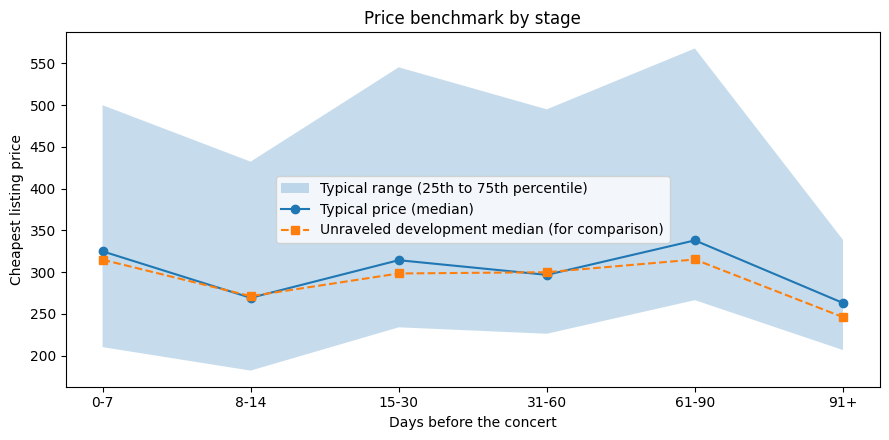

In [ ]:
# Picture: the typical range by stage, with the Unraveled development prices for comparison.
plt.figure(figsize=(9, 4.5))
x = np.arange(len(STAGES))
plt.fill_between(x, BENCHMARK["lower"], BENCHMARK["upper"], alpha=0.25, label="Typical range (25th to 75th percentile)")
plt.plot(x, BENCHMARK["median"], marker="o", label="Typical price (median)")
unraveled_medians = development_ratios.groupby("stage")["get_in"].median().reindex(STAGES)
plt.plot(x, unraveled_medians, marker="s", linestyle="--", label="Unraveled development median (for comparison)")
plt.xticks(x, STAGES)
plt.xlabel("Days before the concert")
plt.ylabel("Cheapest listing price")
plt.title("Price benchmark by stage")
plt.legend()
plt.tight_layout()
plt.show()

---
# Section 4: Model evaluation
**How the model is tested.** Leave-venues-out cross-validation on the development data. The Unraveled development venues are split into 7 groups; each group is held out in turn, and the model is trained on GUTS plus the other groups. A venue's two nights have nearly identical price paths, so a venue is always kept entirely in training or entirely in testing.

Inside each fold, the stage scale factors are re-estimated using **only the training concerts**, so nothing from the held-out venue leaks into the adjustment.

**Comparisons**
- **Logistic regression**: the model from Section 2.
- **Simple rule**: assume today's price stays the same for seven days, and label it against the benchmark.
- **Always Typical**: the most common category, as a floor.

In [ ]:
def cross_validated_predictions(n_splits=7):
    """Out-of-fold predictions for every development Unraveled forecast."""
    development_unraveled_ids = [i for i in unraveled["event_id"].unique() if i not in HELD_OUT_IDS]
    concert_venue = concert_info.loc[development_unraveled_ids, "venue"]
    results = []
    for train_idx, test_idx in GroupKFold(n_splits).split(concert_venue, groups=concert_venue):
        train_ids = set(concert_venue.index[train_idx])
        test_ids = set(concert_venue.index[test_idx])

        # Re-estimate the stage scale from the TRAINING concerts only.
        fold_scale = compute_stage_scale(unraveled[unraveled["event_id"].isin(train_ids)])
        table = usable_rows(build_model_table(daily, fold_scale))

        train = table[table["tour"].eq("guts") | table["event_id"].isin(train_ids)]
        test = table[table["event_id"].isin(test_ids)]
        model = make_model().fit(train[MODEL_FEATURES], train["actual_category"])
        out = test[["event_id", "venue", "target_stage", "actual_category", "rule_category"]].copy()
        out["model_category"] = model.predict(test[MODEL_FEATURES])
        results.append(out)
    return pd.concat(results)


cv = cross_validated_predictions()
print(f"Out-of-fold forecasts: {len(cv):,} across {cv['event_id'].nunique()} concerts at {cv['venue'].nunique()} venues")

Out-of-fold forecasts: 12,820 across 76 concerts at 23 venues


In [ ]:
def venue_bootstrap(frame, columns, repeats=2000, seed=RANDOM_SEED):
    """95% ranges by resampling whole venues. `columns` maps a name to a column of True/False 'correct' flags."""
    rng = np.random.default_rng(seed)
    by_venue = {v: g for v, g in frame.groupby("venue")}
    venues = list(by_venue)
    stats = {name: [] for name in columns}
    stats["model minus rule"] = []
    for _ in range(repeats):
        sample = pd.concat([by_venue[v] for v in rng.choice(venues, len(venues))])
        accuracies = {name: sample[col].mean() for name, col in columns.items()}
        for name, value in accuracies.items():
            stats[name].append(value)
        stats["model minus rule"].append(accuracies["Logistic regression"] - accuracies["Simple rule"])
    return {name: (float(np.quantile(v, .025)), float(np.quantile(v, .975))) for name, v in stats.items()}


def report_block(frame, title):
    """Everything we report for one set of forecasts."""
    frame = frame.assign(model_correct=frame["model_category"] == frame["actual_category"],
                         rule_correct=frame["rule_category"] == frame["actual_category"],
                         typical_correct=frame["actual_category"] == "Typical")
    print("=" * 78)
    print(title)
    print("=" * 78)
    print(f"Forecasts: {len(frame):,} | concerts: {frame['event_id'].nunique()} | venues: {frame['venue'].nunique()}")
    print("Share of real outcomes:", frame["actual_category"].value_counts(normalize=True).reindex(CATEGORIES).round(3).to_dict())

    def scores(predicted):
        return {"accuracy": accuracy_score(frame["actual_category"], predicted),
                "balanced_accuracy": balanced_accuracy_score(frame["actual_category"], predicted),
                "macro_f1": f1_score(frame["actual_category"], predicted, labels=CATEGORIES, average="macro", zero_division=0)}
    comparison = pd.DataFrame({"Logistic regression": scores(frame["model_category"]),
                               "Simple rule (price stays)": scores(frame["rule_category"]),
                               "Always Typical": scores(pd.Series("Typical", index=frame.index))}).T
    print("\nOverall scores:")
    print(comparison.round(3).to_string())

    ranges = venue_bootstrap(frame, {"Logistic regression": "model_correct", "Simple rule": "rule_correct"})
    print("\n95% ranges for accuracy (resampling whole venues):")
    for name in ["Logistic regression", "Simple rule"]:
        print(f"  {name:<22} {ranges[name][0]:.1%} to {ranges[name][1]:.1%}")
    print(f"  Model minus rule        {ranges['model minus rule'][0]:+.1%} to {ranges['model minus rule'][1]:+.1%}")

    print("\nLogistic regression, by category:")
    print(pd.DataFrame(classification_report(frame["actual_category"], frame["model_category"], labels=CATEGORIES,
                                             output_dict=True, zero_division=0)).T.round(3).to_string())
    matrix = pd.DataFrame(confusion_matrix(frame["actual_category"], frame["model_category"], labels=CATEGORIES),
                          index=pd.Index(CATEGORIES, name="What really happened"),
                          columns=pd.Index(CATEGORIES, name="What the model said"))
    print("\nConfusion matrix:")
    print(matrix.to_string())
    return frame


cv = report_block(cv, "SECTION 4 RESULTS: cross-validated on development concerts")

SECTION 4 RESULTS: cross-validated on development concerts
Forecasts: 12,820 | concerts: 76 | venues: 23
Share of real outcomes: {'Below': 0.283, 'Typical': 0.593, 'Above': 0.124}

Overall scores:
                           accuracy  balanced_accuracy  macro_f1
Logistic regression           0.874              0.821     0.835
Simple rule (price stays)     0.874              0.834     0.839
Always Typical                0.593              0.333     0.248

95% ranges for accuracy (resampling whole venues):
  Logistic regression    85.0% to 89.5%
  Simple rule            85.3% to 89.7%
  Model minus rule        -1.3% to +0.9%

Logistic regression, by category:
              precision  recall  f1-score    support
Below             0.894   0.884     0.889   3622.000
Typical           0.879   0.913     0.896   7603.000
Above             0.787   0.665     0.721   1595.000
accuracy          0.874   0.874     0.874      0.874
macro avg         0.853   0.821     0.835  12820.000
weighted avg     

In [ ]:
# How does accuracy change with how close to the show the forecast lands?
by_stage = cv.groupby("target_stage").agg(
    forecasts=("model_correct", "size"),
    model_accuracy=("model_correct", "mean"),
    rule_accuracy=("rule_correct", "mean")).reindex(STAGES)
print("Accuracy by how many days before the concert the forecast lands:")
print(by_stage.round(3).to_string())

Accuracy by how many days before the concert the forecast lands:
              forecasts  model_accuracy  rule_accuracy
target_stage                                          
0-7                 133           0.707          0.737
8-14                133           0.805          0.827
15-30               304           0.885          0.898
31-60               759           0.893          0.889
61-90               955           0.848          0.898
91+               10536           0.877          0.872


**Reading Section 4.** *Precision* answers "when the model said Below, how often was it right?". *Recall* answers "of all the weeks that really were Below, how many did the model catch?". *Balanced accuracy* and *macro F1* average the three categories equally, so a rare category counts as much as a common one. Compare every score with the **Always Typical** row: that is what you get with no skill at all.

# Section 5: Unseen data validation
**What is held out.** The 10 Unraveled concerts dated **November 2026** were excluded from every earlier step: the price adjustment, the benchmark scale, and model training. The final model (Section 2.3) has never seen them.

**What is scored.** For every day with a recorded price, we forecast seven days ahead and compare with the category of the price actually recorded seven days later.


In [ ]:
held_out_table = usable_rows(build_model_table(daily, STAGE_SCALE))
held_out_table = held_out_table[held_out_table["event_id"].isin(HELD_OUT_IDS)]

validation = held_out_table[["event_id", "venue", "target_stage", "actual_category", "rule_category"]].copy()
validation["model_category"] = final_model.predict(held_out_table[MODEL_FEATURES])
validation = report_block(validation, "SECTION 5 RESULTS: unseen November concerts")

per_concert = validation.groupby("event_id").agg(
    forecasts=("model_correct", "size"),
    model_accuracy=("model_correct", "mean"),
    rule_accuracy=("rule_correct", "mean"))
per_concert.insert(0, "concert_date", [concert_info.loc[i, "event_date"].date() for i in per_concert.index])
per_concert.insert(1, "venue", [concert_info.loc[i, "venue"] for i in per_concert.index])
print("\nAccuracy for each held-out concert:")
print(per_concert.sort_values("concert_date").round(3).to_string(index=False))

SECTION 5 RESULTS: unseen November concerts
Forecasts: 1,750 | concerts: 10 | venues: 5
Share of real outcomes: {'Below': 0.088, 'Typical': 0.667, 'Above': 0.245}

Overall scores:
                           accuracy  balanced_accuracy  macro_f1
Logistic regression           0.854              0.738     0.762
Simple rule (price stays)     0.843              0.740     0.756
Always Typical                0.667              0.333     0.267

95% ranges for accuracy (resampling whole venues):
  Logistic regression    81.1% to 89.3%
  Simple rule            81.1% to 87.5%
  Model minus rule        +0.2% to +1.8%

Logistic regression, by category:
              precision  recall  f1-score   support
Below             0.631   0.500     0.558   154.000
Typical           0.866   0.924     0.894  1168.000
Above             0.885   0.790     0.835   428.000
accuracy          0.854   0.854     0.854     0.854
macro avg         0.794   0.738     0.762  1750.000
weighted avg      0.850   0.854     0.85

## Real Data Comparison
**Idea.** Take two concerts and compare what the model says against prices observed independently on SeatData, after my data file ends.



In [ ]:
FORECAST_CONCERTS = ["2026-11-11", "2026-12-19"]

for concert_date in FORECAST_CONCERTS:
    matches = concert_info[concert_info["event_date"] == pd.Timestamp(concert_date)]
    event_id = matches.index[0]
    latest_day = unraveled[unraveled["event_id"] == event_id]["date"].max()
    state = model_table[(model_table["event_id"] == event_id)
                        & (model_table["date"] == latest_day)].iloc[0]

    target_date = latest_day + pd.Timedelta(days=HORIZON_DAYS)
    stage = state["target_stage"]
    low, typical, high = state["lower_ref"], state["median_ref"], state["upper_ref"]

    probs = pd.Series(final_model.predict_proba(
        state[MODEL_FEATURES].to_frame().T.astype(float))[0],
        index=final_model.classes_)[CATEGORIES]
    model_label = probs.idxmax()

    print("=" * 70)
    print(f"CONCERT: {pd.Timestamp(concert_date):%B %d, %Y} | {matches.iloc[0]['venue']}")
    print("=" * 70)
    print(f"Last recorded price: ${state['price_now_adj']:,.2f} on {latest_day:%Y-%m-%d} "
          f"({int(state['days_until_show'])} days before the concert)")
    print(f"Forecast for {target_date:%Y-%m-%d} (7 days later, stage '{stage}'):")
    print(f"  Typical price (median): ${typical:,.2f}")
    print(f"  Typical range:          ${low:,.2f} to ${high:,.2f}")
    print(f"  Below if under ${low:,.2f} | Typical if between | Above if over ${high:,.2f}")
    print(f"Model classification: {model_label.upper()}")
    print("  Probabilities: " + "  ".join(f"{c} {probs[c]:.0%}" for c in CATEGORIES))
    print()

CONCERT: November 11, 2026 | State Farm Arena
Last recorded price: $49.00 on 2026-10-30 (12 days before the concert)
Forecast for 2026-11-06 (7 days later, stage '0-7'):
  Typical price (median): $325.01
  Typical range:          $210.33 to $499.90
  Below if under $210.33 | Typical if between | Above if over $499.90
Model classification: BELOW
  Probabilities: Below 100%  Typical 0%  Above 0%

CONCERT: December 19, 2026 | T-Mobile Arena
Last recorded price: $314.95 on 2026-10-30 (50 days before the concert)
Forecast for 2026-11-06 (7 days later, stage '31-60'):
  Typical price (median): $296.83
  Typical range:          $226.34 to $494.94
  Below if under $226.34 | Typical if between | Above if over $494.94
Model classification: TYPICAL
  Probabilities: Below 2%  Typical 97%  Above 1%



In [ ]:
rows_out = []
for concert_date in FORECAST_CONCERTS:
    matches = concert_info[concert_info["event_date"] == pd.Timestamp(concert_date)]
    event_id = matches.index[0]
    latest_day = unraveled[unraveled["event_id"] == event_id]["date"].max()
    s = model_table[(model_table["event_id"] == event_id)
                    & (model_table["date"] == latest_day)].iloc[0]
    p = pd.Series(final_model.predict_proba(s[MODEL_FEATURES].to_frame().T.astype(float))[0],
                  index=final_model.classes_)
    rows_out.append({
        "concert": f"{pd.Timestamp(concert_date):%b %d, %Y}",
        "last_price": round(s["price_now_adj"], 2),
        "forecast_date": (latest_day + pd.Timedelta(days=HORIZON_DAYS)).date(),
        "typical_range": f"${s['lower_ref']:.0f}-${s['upper_ref']:.0f}",
        "model_says": p.idxmax(),
    })
print(pd.DataFrame(rows_out).to_string(index=False))

     concert  last_price forecast_date typical_range model_says
Nov 11, 2026       49.00    2026-11-06     $210-$500      Below
Dec 19, 2026      314.95    2026-11-06     $226-$495    Typical


**SeatData's Nov 06 prediction for the Nov 11th date**

It is indeed below the typical value so this label was correct

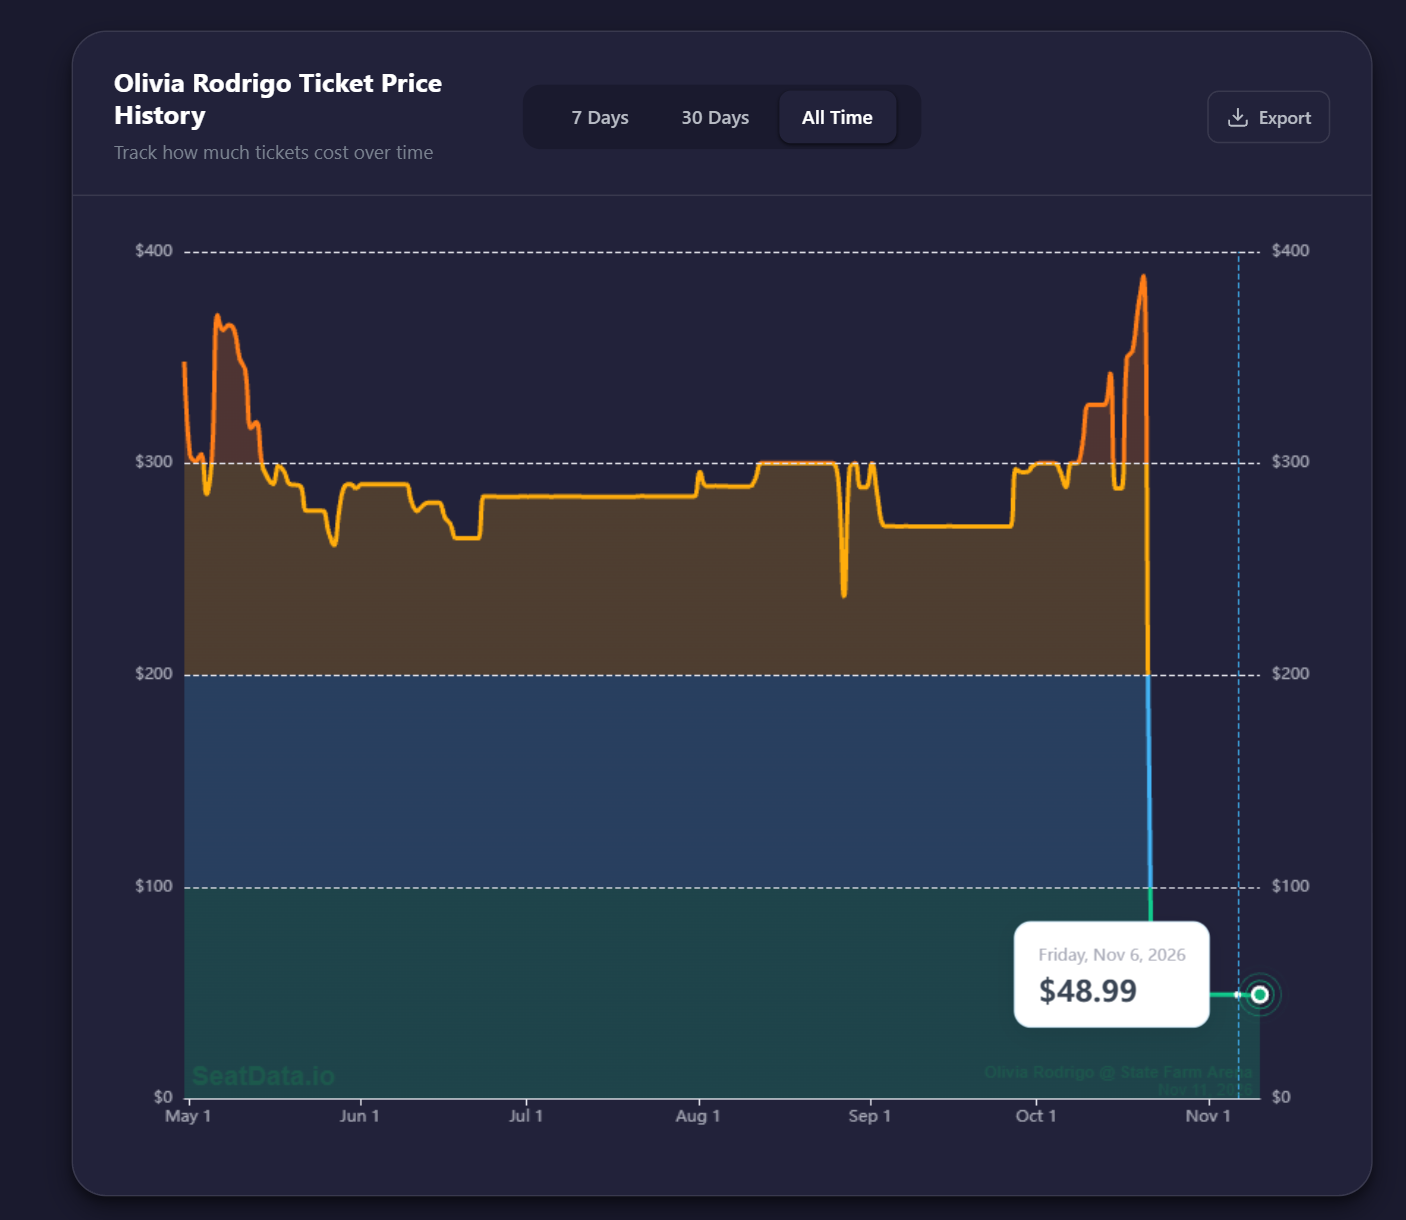

SeatData's Nov 06 prediction for the Dec 19th date

Its typical value so this label was correct too

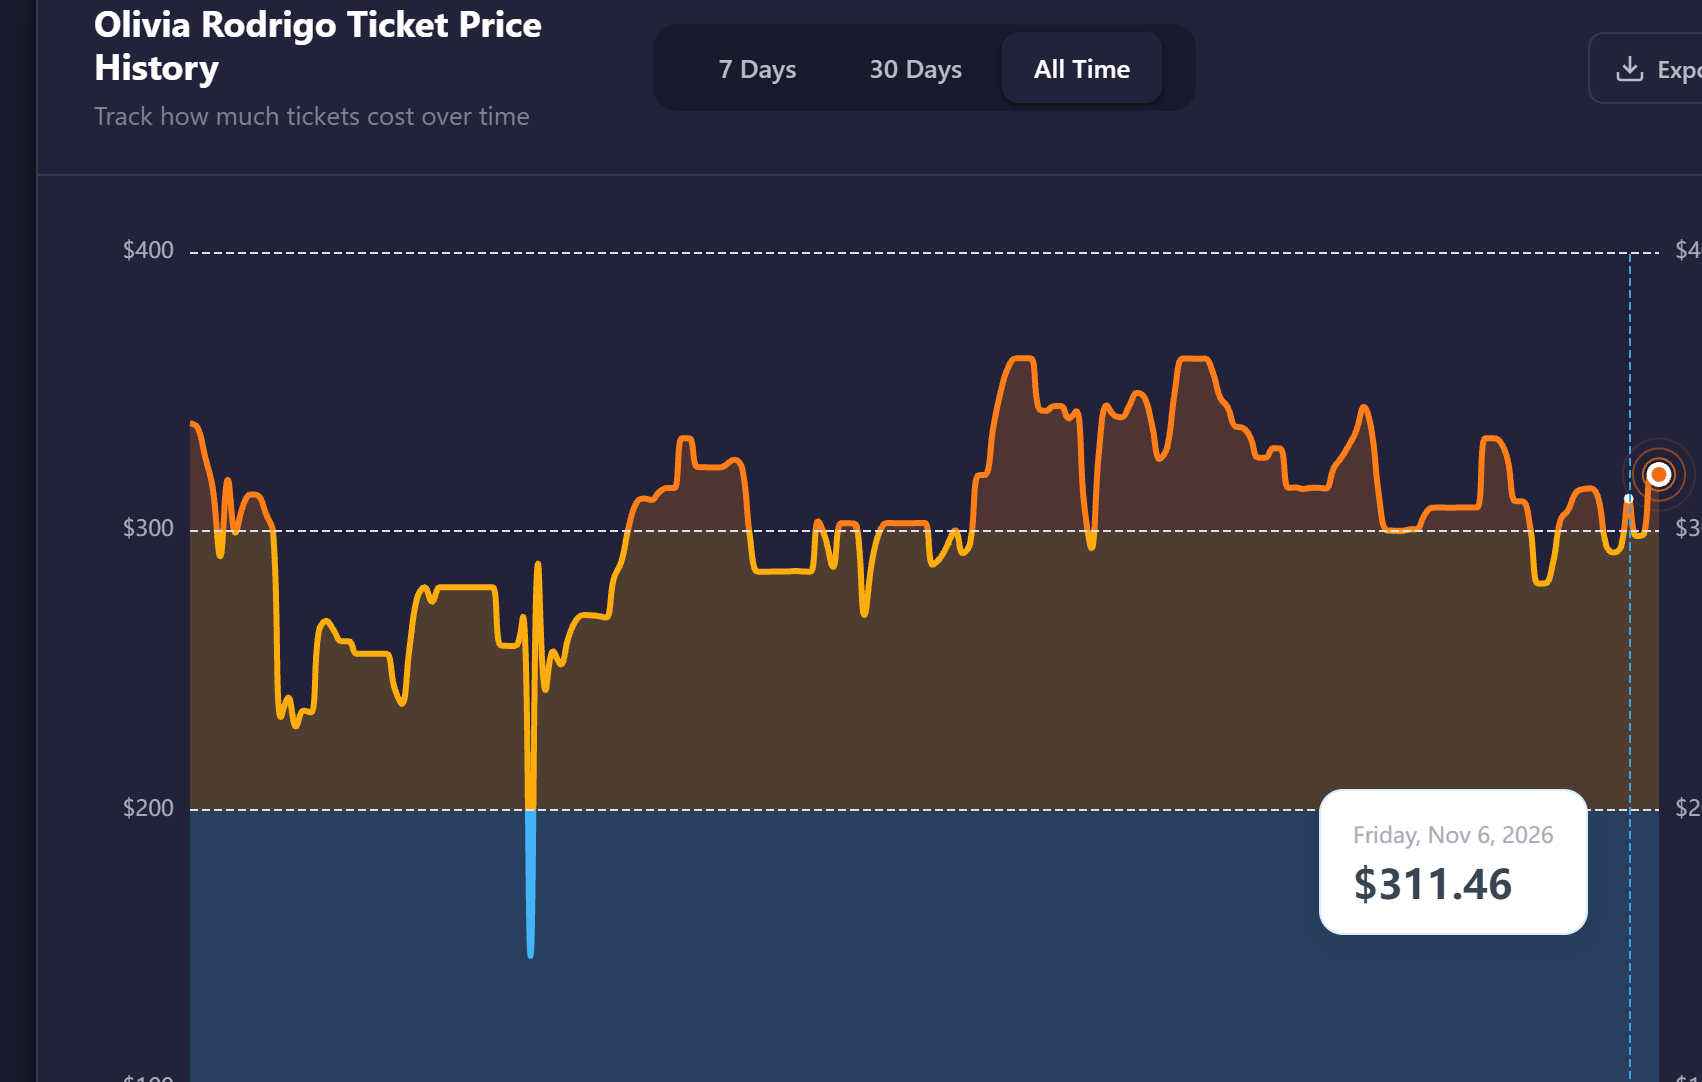